# CBE 130 Lab 7: Boundary Value Problems and the Shooting Method

Many steady-state profiles in chemical engineering, such as the temperature along a heated rod or the reactant concentration inside a catalyst pellet, are fixed by conditions at two different locations instead of at one starting point. These are boundary value problems (BVPs). In this lab, we solve BVPs with the shooting method, which turns a BVP into an initial value problem plus a root-finding problem.

## Learning Objectives

- Convert a second-order boundary value problem into a system of two first-order ODEs.
- Implement the shooting method by combining `solve_ivp` with `root_scalar`.
- Estimate a bracket for the unknown initial condition by checking the sign of the endpoint error.
- Validate shooting results against analytical solutions.
- Apply the shooting method to a catalyst slab with mixed boundary conditions.

## Setup

Run this cell once before working through the lab. NumPy stores the numerical profiles, Matplotlib creates the plots, and SciPy provides `solve_ivp` and `root_scalar`.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

## Part 1: Shooting Method for Dirichlet Boundary Conditions

A second-order BVP gives one condition at each end of the domain, so `solve_ivp` cannot be used directly: it needs both $y$ and $y'$ at the starting point. The shooting method guesses the missing initial slope $s = y'(0)$, solves the IVP, and checks how far the solution misses the right boundary value $y_R$:

$$
E(s) = y_s(x_R) - y_R
$$

The correct slope is the root of $E(s) = 0$. We find it with `root_scalar`, using a bracket $[s_1, s_2]$ where $E(s)$ changes sign.

Before applying the method to a process model, we test it on two problems with known analytical solutions. All variables in Part 1 are dimensionless.

### Question 1.1

Solve the BVP

$$
y'' + y = 0, \qquad 0 \leq x \leq \frac{\pi}{2}
$$

$$
y(0) = 0, \qquad y\left(\frac{\pi}{2}\right) = 1
$$

The general solution is $y = A\sin x + B\cos x$. The condition $y(0) = 0$ gives $B = 0$, and $y(\pi/2) = 1$ gives $A = 1$, so the analytical solution is $y(x) = \sin x$.

Use the shooting method on a 100-point grid in $x$. First print $E(s)$ for 10 trial slopes between 0 and 2 to find a bracket, then use `root_scalar` to find $s$. Print the slope and plot the numerical and analytical solutions.

s = 0.000, E(s) = -1.0000
s = 0.222, E(s) = -0.7778
s = 0.444, E(s) = -0.5556
s = 0.667, E(s) = -0.3334
s = 0.889, E(s) = -0.1111
s = 1.111, E(s) = 0.1111
s = 1.333, E(s) = 0.3333
s = 1.556, E(s) = 0.5555
s = 1.778, E(s) = 0.7777
s = 2.000, E(s) = 0.9999
Initial slope from shooting: s = 1.000036


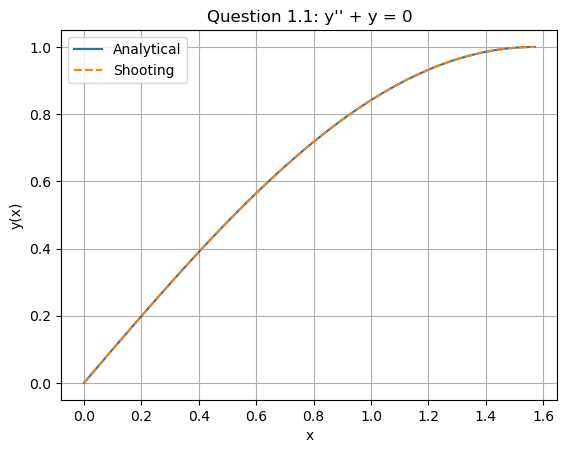

In [5]:
x_initial = 0.0
x_final = np.pi / 2
y_left = 0.0   # y(0)
y_right = 1.0  # y(pi/2)
x_values = np.linspace(x_initial, x_final, 100)

def F(x, Y_n):
    y_current = Y_n[0]
    v_current = Y_n[1]  # v = dy/dx
    dy_dx = v_current
    dv_dx = -y_current
    return [dy_dx, dv_dx]

def shooting_error(y_prime_initial_guess, x_values, y_left, y_right):
    # Solve the IVP with the guessed slope y'(0) = s
    solution = solve_ivp(
        F,
        (x_values[0], x_values[-1]),
        [y_left, y_prime_initial_guess],
        t_eval=x_values
    )
    solution_values = solution.y.T
    y_end = solution_values[-1, 0]
    return y_end - y_right

# Check the sign of E(s) for several slopes to find a bracket
s_trial_values = np.linspace(0.0, 2.0, 10)
for s in s_trial_values:
    error = shooting_error(s, x_values, y_left, y_right)
    print(f"s = {s:.3f}, E(s) = {error:.4f}")

result = root_scalar(
    shooting_error,
    args=(x_values, y_left, y_right),
    bracket=[0.889, 1.111],
    method="brentq"
)
s_root = result.root
print(f"Initial slope from shooting: s = {s_root:.6f}")

# Solve once more with the correct slope
solution = solve_ivp(
    F,
    (x_initial, x_final),
    [y_left, s_root],
    t_eval=x_values
)
solution_values = solution.y.T
y_numerical_values = solution_values[:, 0]
y_exact_values = np.sin(x_values)

plt.figure()
plt.plot(x_values, y_exact_values, label="Analytical")
plt.plot(x_values, y_numerical_values, "--", label="Shooting")
plt.title("Question 1.1: y'' + y = 0")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.legend()
plt.grid(True)
plt.show()

$E(s)$ changes sign between $s = 0.889$ and $s = 1.111$, so $[0, 2]$ is a valid bracket. The shooting slope is $s \approx 1$, matching $y'(0) = \cos 0 = 1$ from the analytical solution, and the two curves overlap.

### Question 1.2

Solve the inhomogeneous BVP

$$
y'' + y = x, \qquad 0 \leq x \leq 1
$$

$$
y(0) = 0, \qquad y(1) = 0
$$

First find the analytical solution by hand. Then use the shooting method on a 200-point grid: print $E(s)$ for 9 trial slopes between $-2$ and 2, and use `root_scalar` to find $s$. Plot the numerical and analytical solutions, plot the absolute error, and print the maximum absolute error.

**Analytical solution.** The homogeneous solution is $y_h = A\sin x + B\cos x$, and a particular solution is $y_p = x$. Then

$$
y = A\sin x + B\cos x + x
$$

The condition $y(0) = 0$ gives $B = 0$. The condition $y(1) = 0$ gives $A\sin 1 + 1 = 0$, so $A = -1/\sin 1$:

$$
y(x) = x - \frac{\sin x}{\sin 1}
$$

The exact initial slope is $y'(0) = 1 - 1/\sin 1 \approx -0.1884$.

s = -2.00, E(s) = -1.5244
s = -1.50, E(s) = -1.1037
s = -1.00, E(s) = -0.6829
s = -0.50, E(s) = -0.2622
s = 0.00, E(s) = 0.1585
s = 0.50, E(s) = 0.5793
s = 1.00, E(s) = 1.0000
s = 1.50, E(s) = 1.4207
s = 2.00, E(s) = 1.8415
Initial slope from shooting: s = -0.188397
Maximum absolute error = 2.04e-05


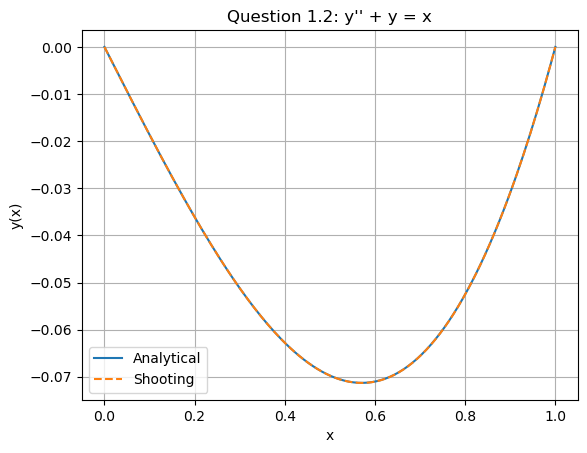

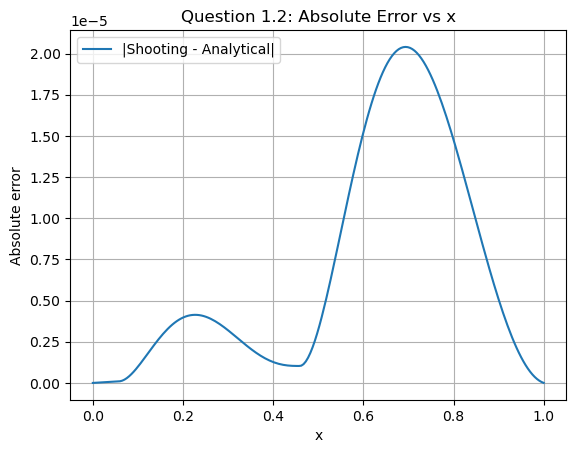

In [7]:
x_initial = 0.0
x_final = 1.0
y_left = 0.0   # y(0)
y_right = 0.0  # y(1)
x_values = np.linspace(x_initial, x_final, 200)

def F(x, Y_n):
    y_current = Y_n[0]
    v_current = Y_n[1]  # v = dy/dx
    dy_dx = v_current
    dv_dx = x - y_current
    return [dy_dx, dv_dx]

def shooting_error(s, x_values, y_left, y_right):
    solution = solve_ivp(
        F,
        (x_values[0], x_values[-1]),
        [y_left, s],
        t_eval=x_values
    )
    solution_values = solution.y.T
    y_end = solution_values[-1, 0]
    return y_end - y_right

s_trial_values = np.linspace(-2.0, 2.0, 9)
for s in s_trial_values:
    error = shooting_error(s, x_values, y_left, y_right)
    print(f"s = {s:.2f}, E(s) = {error:.4f}")

result = root_scalar(
    shooting_error,
    args=(x_values, y_left, y_right),
    bracket=[-0.5, 0.0],
    method="brentq"
)
s_root = result.root
print(f"Initial slope from shooting: s = {s_root:.6f}")

solution = solve_ivp(
    F,
    (x_initial, x_final),
    [y_left, s_root],
    t_eval=x_values
)
solution_values = solution.y.T
y_numerical_values = solution_values[:, 0]
y_exact_values = x_values - np.sin(x_values) / np.sin(1.0)

absolute_error_values = np.abs(y_numerical_values - y_exact_values)
print(f"Maximum absolute error = {np.max(absolute_error_values):.2e}")

plt.figure()
plt.plot(x_values, y_exact_values, label="Analytical")
plt.plot(x_values, y_numerical_values, "--", label="Shooting")
plt.title("Question 1.2: y'' + y = x")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(x_values, absolute_error_values, label="|Shooting - Analytical|")
plt.title("Question 1.2: Absolute Error vs x")
plt.xlabel("x")
plt.ylabel("Absolute error")
plt.legend()
plt.grid(True)
plt.show()

$E(s)$ changes sign between $s = -0.5$ and $s = 0$. The shooting slope matches the exact value $1 - 1/\sin 1 \approx -0.1884$, and the absolute error stays very small across the whole domain.

## Part 2: Catalyst Slab with Mixed Boundary Conditions

A reactant diffuses into a porous catalyst slab from both faces and is consumed inside. Because the slab is symmetric, we model only half of it: $x = 0$ is the center and $x = 1$ is the outer surface. The dimensionless steady-state concentration $y(x)$ satisfies

$$
y'' - y = e^{x}, \qquad 0 \leq x \leq 1
$$

The $-y$ term is first-order consumption, and $e^{x}$ is an extra consumption term that grows toward the surface. Symmetry gives zero flux at the center, and the surface concentration is fixed by the surrounding fluid:

$$
y'(0) = 0, \qquad y(1) = 1
$$

The slope at $x = 0$ is now known, so the unknown in the shooting method is the center concentration $a = y(0)$:

$$
E(a) = y_a(1) - 1
$$

### Question 2.1

First find the analytical solution by hand. Use the particular solution $y_p = Bxe^{x}$.

Then use the shooting method on a 200-point grid with initial conditions $y(0) = a$ and $y'(0) = 0$, and use `root_scalar` with the bracket $[-2, 2]$ to find $a$. Print $a$, plot the numerical and analytical concentration profiles, plot the absolute error, and print the maximum absolute error.

**Analytical solution.** The homogeneous solution is $y_h = C_1 e^{x} + C_2 e^{-x}$. For $y_p = Bxe^{x}$,

$$
y_p'' - y_p = B(x + 2)e^{x} - Bxe^{x} = 2Be^{x}
$$

so $B = 1/2$ and

$$
y = C_1 e^{x} + C_2 e^{-x} + \frac{1}{2}xe^{x}
$$

The condition $y'(0) = 0$ gives $C_1 - C_2 + 1/2 = 0$. Substituting $C_1 = C_2 - 1/2$ into $y(1) = 1$ gives

$$
C_2 = \frac{e}{e^2 + 1}, \qquad C_1 = \frac{e}{e^2 + 1} - \frac{1}{2}
$$

The exact center concentration is $a = y(0) = C_1 + C_2 \approx 0.1480$.

Center concentration from shooting: a = 0.148048
Maximum absolute error = 2.62e-05


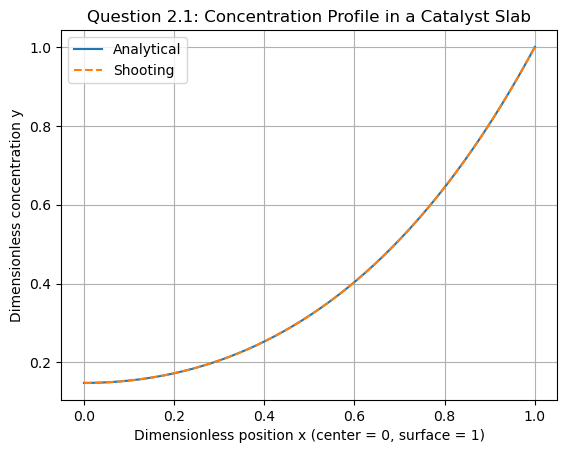

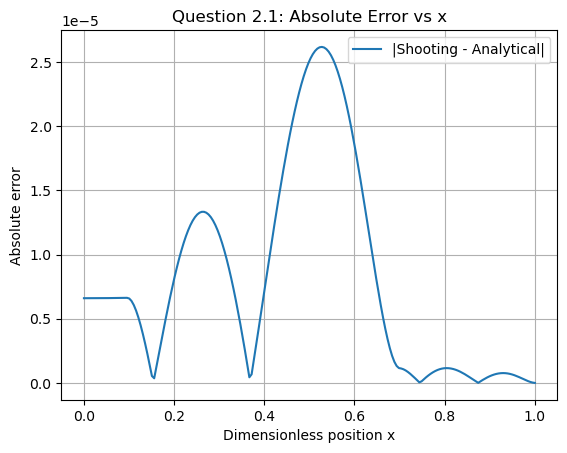

In [8]:
x_initial = 0.0
x_final = 1.0
slope_left = 0.0  # y'(0) = 0, no flux at the center
y_right = 1.0     # y(1) = 1, surface concentration
x_values = np.linspace(x_initial, x_final, 200)

def F(x, Y_n):
    y_current = Y_n[0]
    v_current = Y_n[1]  # v = dy/dx
    dy_dx = v_current
    dv_dx = y_current + np.exp(x)
    return [dy_dx, dv_dx]

def shooting_error(a, x_values, slope_left, y_right):
    # Solve the IVP with the guessed center concentration y(0) = a
    solution = solve_ivp(
        F,
        (x_values[0], x_values[-1]),
        [a, slope_left],
        t_eval=x_values
    )
    solution_values = solution.y.T
    y_end = solution_values[-1, 0]
    return y_end - y_right

result = root_scalar(
    shooting_error,
    args=(x_values, slope_left, y_right),
    bracket=[-2.0, 2.0],
    method="brentq"
)
a_root = result.root
print(f"Center concentration from shooting: a = {a_root:.6f}")

solution = solve_ivp(
    F,
    (x_initial, x_final),
    [a_root, slope_left],
    t_eval=x_values
)
solution_values = solution.y.T
y_numerical_values = solution_values[:, 0]

C2 = np.e / (np.e**2 + 1.0)
C1 = C2 - 0.5
y_exact_values = C1 * np.exp(x_values) + C2 * np.exp(-x_values) + 0.5 * x_values * np.exp(x_values)

absolute_error_values = np.abs(y_numerical_values - y_exact_values)
print(f"Maximum absolute error = {np.max(absolute_error_values):.2e}")

plt.figure()
plt.plot(x_values, y_exact_values, label="Analytical")
plt.plot(x_values, y_numerical_values, "--", label="Shooting")
plt.title("Question 2.1: Concentration Profile in a Catalyst Slab")
plt.xlabel("Dimensionless position x (center = 0, surface = 1)")
plt.ylabel("Dimensionless concentration y")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(x_values, absolute_error_values, label="|Shooting - Analytical|")
plt.title("Question 2.1: Absolute Error vs x")
plt.xlabel("Dimensionless position x")
plt.ylabel("Absolute error")
plt.legend()
plt.grid(True)
plt.show()

The shooting method gives $a \approx 0.148$, matching the analytical center concentration. The concentration is lowest at the center because the reactant is consumed as it diffuses inward, and the profile is flat at $x = 0$ as required by symmetry.